# UTS Pengolahan Citra Digital — Topik 3: Binerisasi Dokumen Berpencahayaan Tidak Merata

**Alur pipeline**

1. **Pra-proses**: konversi ke grayscale dan reduksi derau dengan Gaussian blur.
2. **Koreksi iluminasi**: Black Hat berkernel elips besar untuk menghapus bayangan, dilanjutkan CLAHE untuk memperbaiki kontras lokal.
3. **Binerisasi**: perbandingan Global Otsu, Adaptive Mean, dan Adaptive Gaussian.
4. **Pasca-proses morfologi**: opening, closing, dan penyaringan komponen terhubung berukuran kecil.
5. **Evaluasi**: precision, recall, F1, dan IoU tingkat piksel terhadap mask ground truth.

Sel dibagi menjadi dua kelompok. **Pengaturan dan Modul 1–8** hanya mendefinisikan konstanta dan fungsi, sedangkan **Langkah 1–7** menjalankan pipeline pada data dan menyimpan hasilnya ke folder `hasil/`. Petunjuk instalasi dan struktur folder data ada di `README.md`.

## Pengaturan: impor, konstanta, dan konfigurasi bawaan

In [ ]:
import os
import re
import sys
import time
import json
import argparse
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

SEED = 42
LEBAR_KERJA = 1200
EKSTENSI = (".jpg", ".jpeg", ".png")

KONDISI = {"K1": "Terang merata (jendela)", "K2": "Terang merata (lampu kamar)", "K3": "Bayangan tangan",
           "K4": "Bayangan HP", "K5": "Lampu dari kiri", "K6": "Lampu dari kanan", "K7": "Redup",
           "K8": "Miring", "K9": "Jauh / latar beda", "K10": "Melengkung / kusut"}

SUMBER_PUBLIK = {}

ANALISIS_KEGAGALAN = []

CFG_DEFAULT = dict(metode="adaptive_gauss", ksize_blur=5, sigma_blur=1.0, ukuran_koreksi=51, clip_limit=2.0,
                   block=31, C=10, morf="open_close", se=3, min_area=10, pakai_scratch=True)

## Modul 1: Manajemen dataset

In [ ]:
def _cari_gt(root, kondisi, nama):
    stem = os.path.splitext(os.path.basename(nama))[0]
    for p in (os.path.join(root, kondisi, "gt", stem + ".png"),
              os.path.join(root, "gt_masks", kondisi, stem + ".png"),
              os.path.join(root, "gt_masks", stem + ".png")):
        if os.path.exists(p):
            return p
    return None


def daftar_citra(root):
    items = []
    for i in range(1, 11):
        k = f"K{i}"
        d = os.path.join(root, k)
        if os.path.isdir(d):
            items += [(f"{k}/{f}", k, os.path.join(d, f)) for f in sorted(os.listdir(d)) if f.lower().endswith(EKSTENSI)]
    raw = os.path.join(root, "raw")
    if not items and os.path.isdir(raw):
        for f in sorted(os.listdir(raw)):
            m = re.search(r"_(K\d+)", os.path.splitext(f)[0].upper())
            if f.lower().endswith(EKSTENSI) and m:
                items.append((f, m.group(1), os.path.join(raw, f)))
    return items


def muat_dataset(root, lebar=LEBAR_KERJA):
    baris = []
    for fid, k, path in daftar_citra(root):
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        if img is None:
            print(f"[PERINGATAN] gagal membaca {path}")
            continue
        h, w = img.shape[:2]
        img = cv2.resize(img, (lebar, int(round(h * lebar / w))), interpolation=cv2.INTER_AREA)
        p_gt, gt = _cari_gt(root, k, fid), None
        if p_gt:
            m = cv2.imread(p_gt, cv2.IMREAD_GRAYSCALE)
            gt = cv2.resize(m, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST) > 127
        baris.append({"file": fid, "kondisi": k, "citra": img, "gt": gt})
    df = pd.DataFrame(baris, columns=["file", "kondisi", "citra", "gt"])
    print(f"Total citra termuat: {len(df)} | dengan ground truth: {sum(g is not None for g in df['gt'])}")
    return df


def bagi_dataset(df, rasio_dev=0.6, seed=SEED, csv=None):
    if csv and os.path.exists(csv):
        s = pd.read_csv(csv)
        if set(s.file) == set(df.file):
            peta = dict(zip(s.file, s.split))
            df = df.assign(split=df.file.map(peta))
            dev, uji = df[df.split == "dev"].reset_index(drop=True), df[df.split == "uji"].reset_index(drop=True)
            print(f"Pembagian dibaca dari {csv}: dev {len(dev)} | uji {len(uji)}")
            return dev, uji
    rng = np.random.RandomState(seed)
    uji_idx = []
    for _, g in df.groupby("kondisi"):
        idx = rng.permutation(g.index.to_numpy())
        n_uji = int(np.clip(round((1 - rasio_dev) * len(idx)), 1, len(idx) - 1)) if len(idx) >= 2 else 0
        uji_idx += list(idx[:n_uji])
    df = df.assign(split=np.where(df.index.isin(uji_idx), "uji", "dev"))
    if csv:
        df[["file", "kondisi", "split"]].to_csv(csv, index=False)
    dev, uji = df[df.split == "dev"].reset_index(drop=True), df[df.split == "uji"].reset_index(drop=True)
    print(f"Dev: {len(dev)} citra ({100*len(dev)/len(df):.0f}%) | Uji: {len(uji)} citra ({100*len(uji)/len(df):.0f}%)")
    return dev, uji


def cek_dataset(df, uji):
    publik = [f for f in df.file if f in SUMBER_PUBLIK]
    sendiri = df[~df.file.isin(publik)]
    n_gt = sum(g is not None for g in df["gt"])
    n_uji_tanpa = sum(g is None for g in uji["gt"])
    pct_uji = 100 * len(uji) / max(len(df), 1)
    ok_lisensi = all(len(v) == 2 and all(v) for v in SUMBER_PUBLIK.values())
    baris = [("Total citra >= 50", len(df), len(df) >= 50),
             ("Foto dipotret sendiri >= 30", len(sendiri), len(sendiri) >= 30),
             ("Kondisi berbeda pada foto sendiri >= 3", sendiri.kondisi.nunique(), sendiri.kondisi.nunique() >= 3),
             ("Mask ground truth >= 15", n_gt, n_gt >= 15),
             ("Citra uji tanpa ground truth = 0", n_uji_tanpa, n_uji_tanpa == 0),
             ("Dataset publik punya sumber & lisensi", len(publik), ok_lisensi),
             ("Porsi citra uji sekitar 40% (30-50%)", f"{pct_uji:.0f}%", 30 <= pct_uji <= 50)]
    t = pd.DataFrame(baris, columns=["ketentuan", "nilai", "ok"])
    return t.assign(status=t.ok.map({True: "OK", False: "KURANG"})).drop(columns="ok")

def bagi_per_lembar(df, rasio_uji=0.4, seed=SEED, lembar_uji=None, csv=None):
    lembar = df.file.str.extract(r"^([^_]+)_K\d+")[0]
    assert lembar.notna().all(), "Nama file harus berformat <lembar>_<K>.jpg (mis. A_K3.jpg)"
    df = df.assign(lembar=lembar)
    semua = sorted(df.lembar.unique())
    if lembar_uji is None:
        n_uji = max(1, int(round(rasio_uji * len(semua))))
        lembar_uji = sorted(np.random.RandomState(seed).choice(semua, n_uji, replace=False))
    df = df.assign(split=np.where(df.lembar.isin(lembar_uji), "uji", "dev"))
    dev = df[df.split == "dev"].reset_index(drop=True)
    uji = df[df.split == "uji"].reset_index(drop=True)
    assert not set(dev.lembar) & set(uji.lembar), "masih ada lembar yang sama di dev dan uji"
    assert set(dev.kondisi) == set(uji.kondisi) == set(df.kondisi), "ada kondisi yang tidak terwakili di dev/uji"
    if csv:
        df[["file", "kondisi", "lembar", "split"]].to_csv(csv, index=False)
    print(f"Lembar total: {semua} | lembar uji: {lembar_uji}")
    print(f"Dev: {len(dev)} citra ({100*len(dev)/len(df):.0f}%) | Uji: {len(uji)} citra ({100*len(uji)/len(df):.0f}%)")
    return dev, uji

## Modul 2: Operasi dari nol

Dua operasi dasar yang ditulis sendiri adalah Gaussian blur dan Thresholding Otsu

In [ ]:
def custom_convolve2d(image, kernel):
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    assert kh % 2 == 1 and kw % 2 == 1, "ukuran kernel harus ganjil"
    ph, pw = kh // 2, kw // 2
    pad = np.pad(image.astype(np.float64), ((ph, ph), (pw, pw)), mode="reflect")
    jendela = sliding_window_view(pad, (kh, kw))
    return np.einsum("ijkl,kl->ij", jendela, kernel[::-1, ::-1])


def kernel_gaussian(ukuran, sigma):
    r = ukuran // 2
    ax = np.arange(-r, r + 1, dtype=np.float64)
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2 * sigma ** 2))
    return k / k.sum()


def custom_gaussian_blur(image, kernel_size=5, sigma=1.0):
    assert image.ndim == 2, "hanya citra grayscale"
    out = custom_convolve2d(image, kernel_gaussian(kernel_size, sigma))
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def custom_gaussian_blur_sep(image, kernel_size=5, sigma=1.0):
    assert image.ndim == 2, "hanya citra grayscale"
    ax = np.arange(kernel_size) - kernel_size // 2
    g = np.exp(-ax ** 2 / (2 * sigma ** 2))
    g /= g.sum()
    out = custom_convolve2d(custom_convolve2d(image, g[None, :]), g[:, None])
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def custom_otsu_threshold(image):
    hist = np.bincount(image.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    w0 = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    w1 = 1.0 - w0
    with np.errstate(divide="ignore", invalid="ignore"):
        sigma_b = (mu[-1] * w0 - mu) ** 2 / (w0 * w1)
    return int(np.argmax(np.nan_to_num(sigma_b)))

## Modul 3: Pipeline empat tahap

In [ ]:
def tahap1_preprocessing(image, ksize=5, sigma=1.0, pakai_scratch=True):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    if pakai_scratch:
        return custom_gaussian_blur(gray, ksize, sigma)
    return cv2.GaussianBlur(gray, (ksize, ksize), sigma)


def tahap2_koreksi_iluminasi(gray, ukuran=51, clip_limit=2.0, tile=(8, 8)):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ukuran, ukuran))
    latar = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se)
    blackhat = cv2.subtract(latar, gray)
    rata = cv2.bitwise_not(blackhat)
    return cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile).apply(rata)


def tahap3_binerisasi(gray, metode="adaptive_gauss", block=31, C=10):
    if metode == "otsu":
        return np.where(gray > custom_otsu_threshold(gray), 255, 0).astype(np.uint8)
    cabang = {"adaptive_mean": cv2.ADAPTIVE_THRESH_MEAN_C, "adaptive_gauss": cv2.ADAPTIVE_THRESH_GAUSSIAN_C}
    if metode in cabang:
        return cv2.adaptiveThreshold(gray, 255, cabang[metode], cv2.THRESH_BINARY, block | 1, C)
    raise ValueError(f"metode tidak dikenal: {metode}")


def _buka(m, k):
    if k % 2 == 1:
        return cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    kern = np.ones((k, k), np.uint8)
    return cv2.dilate(cv2.erode(m, kern, anchor=(0, 0)), kern, anchor=(k - 1, k - 1))


def _tutup(m, k):
    if k % 2 == 1:
        return cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    kern = np.ones((k, k), np.uint8)
    return cv2.erode(cv2.dilate(m, kern, anchor=(0, 0)), kern, anchor=(k - 1, k - 1))


def tahap4_postprocessing(biner, morf="open_close", se=3, min_area=10):
    tinta = (biner == 0).astype(np.uint8)
    if morf in ("open", "open_close"):
        tinta = _buka(tinta, se)
    if morf in ("close", "open_close"):
        tinta = _tutup(tinta, se)
    if min_area > 0:
        n, lab, st, _ = cv2.connectedComponentsWithStats(tinta, connectivity=8)
        keep = np.zeros(n, bool)
        keep[1:] = st[1:, cv2.CC_STAT_AREA] >= min_area
        tinta = keep[lab].astype(np.uint8)
    return np.where(tinta > 0, 0, 255).astype(np.uint8)


def tahap4_postprocessing_lama(biner, morf="open_close", se=3, min_area=10):
    tinta = (biner == 0).astype(np.uint8)
    if morf != "none":
        kern = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (se, se))
        if morf in ("open", "open_close"):
            tinta = cv2.morphologyEx(tinta, cv2.MORPH_OPEN, kern)
        if morf in ("close", "open_close"):
            tinta = cv2.morphologyEx(tinta, cv2.MORPH_CLOSE, kern)
    if min_area > 0:
        n, lab, st, _ = cv2.connectedComponentsWithStats(tinta, connectivity=8)
        keep = np.zeros(n, bool)
        keep[1:] = st[1:, cv2.CC_STAT_AREA] >= min_area
        tinta = keep[lab].astype(np.uint8)
    return np.where(tinta > 0, 0, 255).astype(np.uint8)


_CACHE = {}


def reset_cache():
    _CACHE.clear()


def _tahap12(image, cfg, key):
    kc = (key, cfg["ksize_blur"], cfg["sigma_blur"], cfg["pakai_scratch"], cfg["ukuran_koreksi"], cfg["clip_limit"])
    if key is not None and kc in _CACHE:
        return _CACHE[kc]
    g = tahap1_preprocessing(image, cfg["ksize_blur"], cfg["sigma_blur"], cfg["pakai_scratch"])
    g = tahap2_koreksi_iluminasi(g, cfg["ukuran_koreksi"], cfg["clip_limit"])
    if key is not None:
        if len(_CACHE) > 200:
            _CACHE.clear()
        _CACHE[kc] = g
    return g


def pipeline_binerisasi(image, key=None, **kw):
    cfg = {**CFG_DEFAULT, **kw}
    g = _tahap12(image, cfg, key)
    b = tahap3_binerisasi(g, cfg["metode"], cfg["block"], cfg["C"])
    return tahap4_postprocessing(b, cfg["morf"], cfg["se"], cfg["min_area"])


def baseline_otsu_polos(image, key=None):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return np.where(gray > custom_otsu_threshold(gray), 255, 0).astype(np.uint8)

## Modul 4: Verifikasi terhadap pustaka

In [ ]:
def _waktu(fn, *a, ulang=5):
    out = fn(*a)
    ts = []
    for _ in range(ulang):
        t0 = time.perf_counter()
        out = fn(*a)
        ts.append(time.perf_counter() - t0)
    return out, float(np.median(ts))


def verifikasi_scratch(df, n=10, ksize=5, sigma=1.0):
    if len(df) < 10:
        print(f"PERINGATAN: baru {len(df)} citra untuk verifikasi (minimal 10).")
    baris = []
    for _, r in df.head(n).iterrows():
        gray = cv2.cvtColor(r["citra"], cv2.COLOR_BGR2GRAY)
        b_own, w1 = _waktu(custom_gaussian_blur, gray, ksize, sigma, ulang=3)
        b_lib, w2 = _waktu(cv2.GaussianBlur, gray, (ksize, ksize), sigma)
        d = np.abs(b_own.astype(int) - b_lib.astype(int))
        t_own, w3 = _waktu(custom_otsu_threshold, gray)
        t_lib, w4 = _waktu(lambda g: cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0], gray)
        bin_own, bin_lib = np.where(gray > t_own, 255, 0), np.where(gray > t_lib, 255, 0)
        baris.append({"file": r["file"],
                      "blur_piksel_beda": int((d > 0).sum()), "blur_maks_selisih": int(d.max()), "blur_MAE": float(d.mean()),
                      "blur_ms_own": w1 * 1e3, "blur_ms_lib": w2 * 1e3,
                      "otsu_t_own": int(t_own), "otsu_t_lib": int(t_lib),
                      "otsu_piksel_beda": int((bin_own != bin_lib).sum()),
                      "otsu_MAE": float(np.abs(bin_own - bin_lib).mean()),
                      "otsu_ms_own": w3 * 1e3, "otsu_ms_lib": w4 * 1e3})
    v = pd.DataFrame(baris)
    ring = pd.DataFrame({
        "operasi": [f"Gaussian blur {ksize}x{ksize}", "Otsu"],
        "n_citra": [len(v)] * 2,
        "total_piksel_beda": [v.blur_piksel_beda.sum(), v.otsu_piksel_beda.sum()],
        "maks_selisih_intensitas": [v.blur_maks_selisih.max(), 0 if v.otsu_piksel_beda.sum() == 0 else 255],
        "MAE_rata2": [v.blur_MAE.mean(), v.otsu_MAE.mean()],
        "ms_own": [v.blur_ms_own.median(), v.otsu_ms_own.median()],
        "ms_lib": [v.blur_ms_lib.median(), v.otsu_ms_lib.median()]})
    ring["selisih_waktu_ms"] = ring.ms_own - ring.ms_lib
    ring["rasio_own/lib"] = ring.ms_own / ring.ms_lib
    ok = bool((v.otsu_t_own == v.otsu_t_lib).all() and v.blur_maks_selisih.max() <= 1 and len(v) >= 10)
    return v, ring.round(4), ok


def verifikasi_konvolusi(df, n=10):
    kernels = {"Sobel-x (asimetris)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
               "Sobel-y (asimetris)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
               "Gaussian 5x5 (simetris)": kernel_gaussian(5, 1.0)}
    baris = []
    for _, r in df.head(n).iterrows():
        g = cv2.cvtColor(r["citra"], cv2.COLOR_BGR2GRAY).astype(np.float64)
        for nama, k in kernels.items():
            own = custom_convolve2d(g, k)
            lib = cv2.filter2D(g, -1, k[::-1, ::-1], borderType=cv2.BORDER_REFLECT_101)
            lib_tanpa_flip = cv2.filter2D(g, -1, k, borderType=cv2.BORDER_REFLECT_101)
            baris.append({"kernel": nama, "file": r["file"],
                          "maks_selisih": np.abs(own - lib).max(), "MAE": np.abs(own - lib).mean(),
                          "selisih_jika_tidak_dibalik": np.abs(own - lib_tanpa_flip).max()})
    d = pd.DataFrame(baris)
    ring = d.groupby("kernel").agg(n_citra=("file", "count"), maks_selisih=("maks_selisih", "max"),
                                   MAE_rata2=("MAE", "mean"),
                                   selisih_jika_tidak_dibalik=("selisih_jika_tidak_dibalik", "max"))
    return d, ring, bool(ring.maks_selisih.max() < 1e-6 and len(d.file.unique()) >= 10)

## Modul 5: Evaluasi metrik

In [ ]:
def hitung_metrik(biner, gt):
    pred = biner == 0
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    return {"precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0,
            "iou": tp / (tp + fp + fn) if tp + fp + fn else 0.0}


def evaluasi(df, fn):
    baris = []
    for _, r in df.iterrows():
        if r["gt"] is None:
            continue
        baris.append({"file": r["file"], "kondisi": r["kondisi"], **hitung_metrik(fn(r["citra"], r["file"]), r["gt"])})
    return pd.DataFrame(baris)


def fn_pipeline(cfg):
    return lambda im, key: pipeline_binerisasi(im, key=key, **cfg)


def f1_rata(df, cfg):
    return float(evaluasi(df, fn_pipeline(cfg)).f1.mean())

## Modul 6: Eksperimen perbandingan metode dan penyetelan parameter (hanya citra pengembangan)

In [ ]:
GRID_UKURAN = (51, 71, 91, 111)
GRID_BLOCK = (15, 25, 35, 51)
GRID_C = (4, 7, 10, 15)


def _grid():
    seg = [("otsu", {})]
    for m in ("adaptive_mean", "adaptive_gauss"):
        seg += [(m, {"block": b, "C": c}) for b in GRID_BLOCK for c in GRID_C]
    for u in GRID_UKURAN:
        for m, p in seg:
            yield {"ukuran_koreksi": u, "metode": m, **p}


def cek_tepi_grid(cfg):
    cek = [("ukuran_koreksi", GRID_UKURAN)]
    if cfg["metode"] != "otsu":
        cek += [("block", GRID_BLOCK), ("C", GRID_C)]
    ada = False
    for k, g in cek:
        if cfg[k] in (min(g), max(g)):
            ada = True
            print(f"[PERINGATAN] {k}={cfg[k]} ada di tepi grid {g}; perluas grid ke arah itu lalu jalankan ulang.")
    if not ada:
        print("Pemenang grid berada di dalam rentang grid (tidak di tepi).")
    return not ada


def _cfg_dari_baris(r):
    cfg = dict(CFG_DEFAULT)
    for k in ("metode", "ukuran_koreksi", "block", "C"):
        if k in r and pd.notna(r[k]):
            cfg[k] = r[k] if k == "metode" else int(r[k])
    return cfg


def setel_parameter(dev):
    assert any(g is not None for g in dev["gt"]), "Belum ada ground truth untuk citra dev."
    reset_cache()
    tun = pd.DataFrame([{**c, "f1_dev": f1_rata(dev, {**CFG_DEFAULT, **c})} for c in _grid()])
    tun = tun.sort_values("f1_dev", ascending=False).reset_index(drop=True)
    cfg = _cfg_dari_baris(tun.iloc[0])

    percobaan = {}

    def coba(nama, kandidat, set_cfg):
        reset_cache()
        hasil = {lab: f1_rata(dev, set_cfg(dict(cfg), val)) for lab, val in kandidat.items()}
        percobaan[nama] = hasil
        return kandidat[max(hasil, key=hasil.get)]

    ks, sg = coba("blur (ukuran, sigma)", {"3,0.8": (3, 0.8), "5,1.0": (5, 1.0), "7,1.5": (7, 1.5)},
                  lambda c, v: {**c, "ksize_blur": v[0], "sigma_blur": v[1]})
    cfg.update(ksize_blur=ks, sigma_blur=sg)

    cfg["clip_limit"] = coba("clip_limit CLAHE", {"1.0": 1.0, "2.0": 2.0, "4.0": 4.0}, lambda c, v: {**c, "clip_limit": v})

    morf_kand = {"none": ("none", 3)}
    for j in ("open", "close", "open_close"):
        for s in (2, 3, 5):
            morf_kand[f"{j}/{s}"] = (j, s)
    mj, ms = coba("morfologi (jenis/ukuran SE)", morf_kand, lambda c, v: {**c, "morf": v[0], "se": v[1]})
    cfg.update(morf=mj, se=ms)

    cfg["min_area"] = coba("min_area (bintik)", {str(a): a for a in (5, 10, 20, 40)}, lambda c, v: {**c, "min_area": v})
    reset_cache()

    def ringkas(h):
        return "; ".join(f"{k}={v:.3f}" for k, v in h.items())

    alasan = pd.DataFrame([
        ["ukuran koreksi iluminasi", cfg["ukuran_koreksi"],
         f"grid {GRID_UKURAN} (tuning_dev.csv); harus > tebal goresan huruf dan > tinggi blok judul gelap, tetapi cukup kecil untuk mengikuti bayangan"],
        ["metode segmentasi", cfg["metode"], "F1 dev tertinggi pada grid (perbandingan_metode.csv)"],
        ["block / C", f'{cfg["block"]} / {cfg["C"]}', f"grid block {GRID_BLOCK} x C {GRID_C} pada metode adaptif"],
        ["blur (ukuran, sigma)", f'{cfg["ksize_blur"]}, {cfg["sigma_blur"]}', "F1 dev: " + ringkas(percobaan["blur (ukuran, sigma)"])],
        ["clip_limit CLAHE", cfg["clip_limit"], "F1 dev: " + ringkas(percobaan["clip_limit CLAHE"])],
        ["morfologi / SE", f'{cfg["morf"]} / {cfg["se"]}', "F1 dev: " + ringkas(percobaan["morfologi (jenis/ukuran SE)"])],
        ["min_area", cfg["min_area"], "F1 dev: " + ringkas(percobaan["min_area (bintik)"])],
    ], columns=["parameter", "nilai terpilih", "bukti hasil percobaan (DEV)"])
    return cfg, tun, percobaan, alasan


def komparasi_metode(tun, dev, uji, cfg_akhir):
    baris = []
    for m, nama in (("otsu", "Global Otsu"), ("adaptive_mean", "Adaptive Mean"), ("adaptive_gauss", "Adaptive Gaussian")):
        r = tun[tun.metode == m].iloc[0]
        ganti = {k: v for k, v in _cfg_dari_baris(r).items() if k in ("metode", "ukuran_koreksi", "block", "C")}
        cfg_m = {**cfg_akhir, **ganti}
        e = evaluasi(uji, fn_pipeline(cfg_m))
        baris.append({"metode": nama, "ukuran_koreksi": cfg_m["ukuran_koreksi"],
                      "block": cfg_m["block"] if m != "otsu" else None,
                      "C": cfg_m["C"] if m != "otsu" else None,
                      "f1_dev": f1_rata(dev, cfg_m), "precision_uji": e.precision.mean(),
                      "recall_uji": e.recall.mean(), "f1_uji": e.f1.mean()})
    return pd.DataFrame(baris).round(4)

## Modul 7: Analisis kegagalan

In [ ]:
def _petunjuk(r):
    if r["precision"] < r["recall"] - 0.1:
        return "Banyak positif palsu (merah): cek tahap 2 (bayangan/tepi cahaya belum terhapus) dan tahap 3 (ambang terlalu longgar)."
    if r["recall"] < r["precision"] - 0.1:
        return "Banyak tinta hilang (biru): cek tahap 3 (ambang terlalu ketat, goresan tipis) dan tahap 4 (opening/min_area terlalu agresif)."
    return "Salah ke dua arah: cek tahap 1-2 (derau atau pencahayaan sangat tidak merata, mis. redup/miring)."


def analisis_kegagalan(uji, cfg, out, n=3):
    e = evaluasi(uji, fn_pipeline(cfg)).nsmallest(n, "f1").reset_index(drop=True)
    idx = uji.set_index("file")
    for i, r in e.iterrows():
        img, gt = idx.loc[r["file"], "citra"], idx.loc[r["file"], "gt"]
        pred = pipeline_binerisasi(img, **cfg) == 0
        err = np.full(gt.shape + (3,), 255, np.uint8)
        err[pred & gt] = (0, 0, 0); err[pred & ~gt] = (255, 0, 0); err[~pred & gt] = (0, 0, 255)
        fig, ax = plt.subplots(1, 4, figsize=(18, 6))
        for a, im, t in zip(ax, (cv2.cvtColor(img, cv2.COLOR_BGR2RGB), gt, pred, err), ("Asli", "Ground truth", "Prediksi", "Galat")):
            a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
        fig.suptitle(f"#{i+1} {r['file']} ({KONDISI.get(r['kondisi'], '')})  F1={r['f1']:.3f}  P={r['precision']:.3f}  R={r['recall']:.3f}")
        nama = re.sub(r"[^A-Za-z0-9_]", "_", os.path.splitext(r["file"])[0])
        fig.savefig(os.path.join(out, f"gagal_{i+1}_{nama}.png"), dpi=80, bbox_inches="tight"); plt.show()
        e.loc[i, "petunjuk_awal"] = _petunjuk(r)
    return e.round(4)

## Modul 8: Data sintetis

In [ ]:
def buat_data_demo(root, per_kondisi=5):
    rng = np.random.RandomState(1)
    ys, xs = np.mgrid[0:900, 0:700]
    for k in range(1, 11):
        os.makedirs(f"{root}/K{k}/gt", exist_ok=True)
        ang = k * 0.6
        grad = xs * np.cos(ang) + ys * np.sin(ang)
        grad = (grad - grad.min()) / (grad.max() - grad.min())
        for j in range(per_kondisi):
            kanvas = np.full((900, 700), 255, np.uint8)
            for i in range(8):
                cv2.putText(kanvas, f"baris teks contoh {i} lembar {j}", (20, 80 + i * 100),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.9, 0, 2, cv2.LINE_AA)
            gt = ((kanvas < 128) * 255).astype(np.uint8)
            ilum = 0.95 - (0.1 + 0.05 * k) * grad
            if k % 3 == 0:
                ilum = ilum - 0.4 * np.exp(-((xs - 200 - 40 * j) ** 2 + (ys - 450) ** 2) / 60000.0)
            img = np.clip(kanvas * np.clip(ilum, 0.2, 1) + rng.randn(900, 700) * 3, 0, 255).astype(np.uint8)
            cv2.imwrite(f"{root}/K{k}/dok{j}.jpg", img)
            cv2.imwrite(f"{root}/K{k}/gt/dok{j}.png", gt)

## Langkah 1: Lokasi data dan unggah berkas

In [ ]:
IN_COLAB = "google.colab" in sys.modules
DEMO = False
BASE = "/content/uts_topik3" if IN_COLAB else os.getcwd()
ROOT = BASE + ("/data_demo" if DEMO else "/data")
OUT = BASE + "/hasil"
for d in (ROOT + "/raw", ROOT + "/gt_masks", OUT + "/biner"):
    os.makedirs(d, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
try:
    display
except NameError:
    display = print

def unggah_zip(tujuan, judul):
    import zipfile
    from google.colab import files
    print(judul)
    for nama, isi in files.upload().items():
        if nama.lower().endswith(".zip"):
            with zipfile.ZipFile(nama) as z:
                for m in z.namelist():
                    if m.endswith("/") or m.startswith("__MACOSX"):
                        continue
                    open(os.path.join(tujuan, os.path.basename(m)), "wb").write(z.read(m))
        else:
            open(os.path.join(tujuan, nama), "wb").write(isi)

if DEMO:
    buat_data_demo(ROOT)
    print("MODE DEMO: data sintetis (BUKAN data asli).")
elif IN_COLAB:
    if not os.listdir(ROOT + "/raw"):
        unggah_zip(ROOT + "/raw", "Pilih foto.zip (foto dokumen):")
    if not os.listdir(ROOT + "/gt_masks"):
        unggah_zip(ROOT + "/gt_masks", "Pilih mask.zip (mask ground truth PNG):")
print("Folder kerja:", BASE)

Pilih foto.zip (foto dokumen):


Saving foto.zip to foto.zip
Pilih mask.zip (mask ground truth PNG):


Saving mask.zip to mask.zip
Folder kerja: /content/uts_topik3


## Langkah 2: Muat data, bagi menjadi dev dan uji, lalu periksa ketentuan dataset

In [ ]:
df = muat_dataset(ROOT)
assert len(df) > 0, f"Tidak ada citra di {ROOT}"
if DEMO:
    dev, uji = bagi_dataset(df)
else:
    dev, uji = bagi_per_lembar(df, csv=os.path.join(ROOT, "split.csv"))
cek = cek_dataset(df, uji)
display(cek)
display(df.assign(split=df.file.map(dict(zip(dev.file, ["dev"] * len(dev)), **dict(zip(uji.file, ["uji"] * len(uji))))))
          .groupby(["kondisi", "split"]).size().unstack(fill_value=0)
          .reindex(sorted(df.kondisi.unique(), key=lambda x: int(x[1:]))))

Total citra termuat: 50 | dengan ground truth: 50
Lembar total: ['A', 'B', 'C', 'D', 'E'] | lembar uji: [np.str_('B'), np.str_('E')]
Dev: 30 citra (60%) | Uji: 20 citra (40%)


,ketentuan,nilai,status
0,Total citra >= 50,50,OK
1,Foto dipotret sendiri >= 30,50,OK
2,Kondisi berbeda pada foto sendiri >= 3,10,OK
3,Mask ground truth >= 15,50,OK
4,Citra uji tanpa ground truth = 0,0,OK
5,Dataset publik punya sumber & lisensi,0,OK
6,Porsi citra uji sekitar 40% (30-50%),40%,OK


split,dev,uji
kondisi,,
K1,3,2
K2,3,2
K3,3,2
K4,3,2
K5,3,2
K6,3,2
K7,3,2
K8,3,2
K9,3,2


## Langkah 3: Verifikasi operasi buatan sendiri terhadap OpenCV

In [ ]:
v, ring, verif_ok = verifikasi_scratch(df, n=10)
v.round(3).to_csv(OUT + "/verifikasi.csv", index=False); ring.to_csv(OUT + "/verifikasi_ringkasan.csv", index=False)
display(ring)
print("Verifikasi lolos:", verif_ok)
display(v.round(3))

,operasi,n_citra,total_piksel_beda,maks_selisih_intensitas,MAE_rata2,ms_own,ms_lib,selisih_waktu_ms,rasio_own/lib
0,Gaussian blur 5x5,10,66899,1,0.0036,152.2107,2.3900,149.8206,63.6860
1,Otsu,10,0,0,0.0000,9.4294,2.4981,6.9312,3.7746


Verifikasi lolos: True


,file,blur_piksel_beda,blur_maks_selisih,blur_MAE,blur_ms_own,blur_ms_lib,otsu_t_own,otsu_t_lib,otsu_piksel_beda,otsu_MAE,otsu_ms_own,otsu_ms_lib
0,A_K1.png,7156,1,0.004,138.916,2.521,82,82,0,0.0,8.975,2.381
1,A_K10.png,8685,1,0.005,157.120,5.381,70,70,0,0.0,10.454,2.670
2,A_K2.png,7113,1,0.004,208.174,3.519,76,76,0,0.0,10.154,2.461
3,A_K3.png,7366,1,0.004,213.471,4.037,79,79,0,0.0,10.987,2.679
4,A_K4.png,7370,1,0.004,203.503,3.424,79,79,0,0.0,10.530,2.846
5,A_K5.png,6676,1,0.003,149.694,2.018,63,63,0,0.0,7.892,2.082
6,A_K6.png,6661,1,0.003,128.720,2.054,66,66,0,0.0,8.155,2.067
7,A_K7.png,8313,1,0.004,142.389,2.205,33,33,0,0.0,8.498,2.596
8,A_K8.png,5220,1,0.003,154.727,2.259,84,84,0,0.0,9.883,2.536
9,A_K9.png,2339,1,0.003,64.401,0.981,103,103,0,0.0,4.627,1.090


### Verifikasi lanjutan: konvolusi 2D langsung dan Gaussian separabel

In [ ]:
vk_detail, vk, verif_konv_ok = verifikasi_konvolusi(df, n=10)
vk_detail.to_csv(OUT + "/verifikasi_konvolusi.csv", index=False)
display(vk)
print("Verifikasi konvolusi langsung lolos:", verif_konv_ok)

baris = []
for _, r in df.head(10).iterrows():
    gray = cv2.cvtColor(r["citra"], cv2.COLOR_BGR2GRAY)
    a, w_a = _waktu(custom_gaussian_blur, gray, 5, 1.0, ulang=3)
    b, w_b = _waktu(custom_gaussian_blur_sep, gray, 5, 1.0, ulang=3)
    c, w_c = _waktu(cv2.GaussianBlur, gray, (5, 5), 1.0)
    baris.append({"file": r["file"],
                  "piksel_beda_2D_vs_sep": int((a != b).sum()),
                  "piksel_beda_sep_vs_cv2": int((b.astype(int) != c.astype(int)).sum()),
                  "maks_selisih_sep_vs_cv2": int(np.abs(b.astype(int) - c.astype(int)).max()),
                  "ms_2D": w_a * 1e3, "ms_separable": w_b * 1e3, "ms_cv2": w_c * 1e3})
sep = pd.DataFrame(baris)
ring_sep = pd.DataFrame({"n_citra": [len(sep)],
                         "total_piksel_beda_2D_vs_sep": [sep.piksel_beda_2D_vs_sep.sum()],
                         "total_piksel_beda_sep_vs_cv2": [sep.piksel_beda_sep_vs_cv2.sum()],
                         "maks_selisih_sep_vs_cv2": [sep.maks_selisih_sep_vs_cv2.max()],
                         "ms_2D_median": [sep.ms_2D.median()], "ms_separable_median": [sep.ms_separable.median()],
                         "ms_cv2_median": [sep.ms_cv2.median()]})
ring_sep["percepatan_sep_vs_2D"] = ring_sep.ms_2D_median / ring_sep.ms_separable_median
ring_sep["rasio_sep/cv2"] = ring_sep.ms_separable_median / ring_sep.ms_cv2_median
ring_sep.round(3).to_csv(OUT + "/verifikasi_separable.csv", index=False)
display(ring_sep.round(3))

,n_citra,maks_selisih,MAE_rata2,selisih_jika_tidak_dibalik
kernel,,,,
Gaussian 5x5 (simetris),10,1.705303e-13,1.056689e-14,1.705303e-13
Sobel-x (asimetris),10,0.000000e+00,0.000000e+00,1.980000e+03
Sobel-y (asimetris),10,0.000000e+00,0.000000e+00,1.926000e+03


Verifikasi konvolusi langsung lolos: True


,n_citra,total_piksel_beda_2D_vs_sep,total_piksel_beda_sep_vs_cv2,maks_selisih_sep_vs_cv2,ms_2D_median,ms_separable_median,ms_cv2_median,percepatan_sep_vs_2D,rasio_sep/cv2
0,10,0,66899,1,158.454,58.347,2.368,2.716,24.638


## Langkah 4: Penyetelan parameter dan perbandingan metode

In [ ]:
cfg, tun, percobaan, alasan = setel_parameter(dev)
tun.to_csv(OUT + "/tuning_dev.csv", index=False); alasan.to_csv(OUT + "/alasan_parameter.csv", index=False)
for nama, h in percobaan.items():
    print(f"F1 dev vs {nama}:", {k: round(x, 4) for k, x in h.items()})
print("KONFIGURASI TERPILIH:", cfg)
cek_tepi_grid(cfg)
json.dump({k: (x.item() if hasattr(x, "item") else x) for k, x in cfg.items()}, open(OUT + "/konfigurasi_terpilih.json", "w"), indent=2)
display(alasan)

F1 dev vs blur (ukuran, sigma): {'3,0.8': 0.49, '5,1.0': 0.496, '7,1.5': 0.4906}
F1 dev vs clip_limit CLAHE: {'1.0': 0.4969, '2.0': 0.496, '4.0': 0.4666}
F1 dev vs morfologi (jenis/ukuran SE): {'none': 0.5152, 'open/2': 0.514, 'open/3': 0.5028, 'open/5': 0.2739, 'close/2': 0.5122, 'close/3': 0.5053, 'close/5': 0.49, 'open_close/2': 0.5114, 'open_close/3': 0.4969, 'open_close/5': 0.2752}
F1 dev vs min_area (bintik): {'5': 0.5145, '10': 0.5152, '20': 0.5153, '40': 0.5084}
KONFIGURASI TERPILIH: {'metode': 'adaptive_gauss', 'ksize_blur': 5, 'sigma_blur': 1.0, 'ukuran_koreksi': 111, 'clip_limit': 1.0, 'block': 25, 'C': 7, 'morf': 'none', 'se': 3, 'min_area': 20, 'pakai_scratch': True}
[PERINGATAN] ukuran_koreksi=111 ada di tepi grid (51, 71, 91, 111); perluas grid ke arah itu lalu jalankan ulang.


,parameter,nilai terpilih,bukti hasil percobaan (DEV)
0,ukuran koreksi iluminasi,111,"grid (51, 71, 91, 111) (tuning_dev.csv); harus > tebal goresan huruf dan > tinggi blok judul gelap, tetapi cukup kec..."
1,metode segmentasi,adaptive_gauss,F1 dev tertinggi pada grid (perbandingan_metode.csv)
2,block / C,25 / 7,"grid block (15, 25, 35, 51) x C (4, 7, 10, 15) pada metode adaptif"
3,"blur (ukuran, sigma)","5, 1.0","F1 dev: 3,0.8=0.490; 5,1.0=0.496; 7,1.5=0.491"
4,clip_limit CLAHE,1.0,F1 dev: 1.0=0.497; 2.0=0.496; 4.0=0.467
5,morfologi / SE,none / 3,F1 dev: none=0.515; open/2=0.514; open/3=0.503; open/5=0.274; close/2=0.512; close/3=0.505; close/5=0.490; open_clos...
6,min_area,20,F1 dev: 5=0.515; 10=0.515; 20=0.515; 40=0.508


### Bukti pergeseran morfologi pada kernel genap

In [ ]:
def f1_varian_tahap4(data, cfg, fn_tahap4, dy=0, dx=0):
    f = []
    for _, r in data.iterrows():
        if r["gt"] is None:
            continue
        g = _tahap12(r["citra"], cfg, r["file"])
        b = tahap3_binerisasi(g, cfg["metode"], cfg["block"], cfg["C"])
        out = fn_tahap4(b, cfg["morf"], cfg["se"], cfg["min_area"])
        if dy or dx:
            out = np.roll(out, (dy, dx), axis=(0, 1))
        f.append(hitung_metrik(out, r["gt"])["f1"])
    return float(np.mean(f))


c = {**cfg, "morf": "open_close", "se": 2}
bukti = [("tahap 4 LAMA (kernel genap bergeser)", f1_varian_tahap4(dev, c, tahap4_postprocessing_lama)),
         ("tahap 4 BARU (tanpa geser)", f1_varian_tahap4(dev, c, tahap4_postprocessing))]
for dy, dx in [(1, 1), (-1, -1), (1, 0), (0, 1)]:
    bukti.append((f"LAMA + hasil digeser ({dy},{dx})", f1_varian_tahap4(dev, c, tahap4_postprocessing_lama, dy, dx)))
bukti = pd.DataFrame(bukti, columns=["varian (open_close, SE 2x2, DEV)", "f1_dev"]).round(4)
bukti.to_csv(OUT + "/bukti_pergeseran_morfologi.csv", index=False)
display(bukti)

,"varian (open_close, SE 2x2, DEV)",f1_dev
0,tahap 4 LAMA (kernel genap bergeser),0.4002
1,tahap 4 BARU (tanpa geser),0.5114
2,"LAMA + hasil digeser (1,1)",0.2768
3,"LAMA + hasil digeser (-1,-1)",0.5199
4,"LAMA + hasil digeser (1,0)",0.3321
5,"LAMA + hasil digeser (0,1)",0.3283


In [ ]:
komp = komparasi_metode(tun, dev, uji, cfg)
komp.to_csv(OUT + "/perbandingan_metode.csv", index=False)
print("Perbandingan metode (dipilih dari F1 DEV; kolom *_uji hanya dilaporkan; parameter tahap 1, 2, 4 sama untuk semua baris):")
display(komp)

Perbandingan metode (dipilih dari F1 DEV; kolom *_uji hanya dilaporkan; parameter tahap 1, 2, 4 sama untuk semua baris):


,metode,ukuran_koreksi,block,C,f1_dev,precision_uji,recall_uji,f1_uji
0,Global Otsu,51,NaN,NaN,0.4620,0.5375,0.5085,0.5198
1,Adaptive Mean,111,15.0,10.0,0.5091,0.6527,0.4988,0.5626
2,Adaptive Gaussian,111,25.0,7.0,0.5153,0.6481,0.5073,0.5663


## Langkah 5: Hasil akhir pada citra uji (keseluruhan dan per kondisi)

== Keseluruhan (UJI) ==


,precision,recall,f1,iou
metode,,,,
baseline_otsu_polos,0.0604,0.6479,0.1094,0.0583
pipeline_terpilih,0.6481,0.5073,0.5663,0.3985


== F1 per kondisi (UJI) ==


metode,nama,baseline_otsu_polos,pipeline_terpilih
kondisi,,,
K1,Terang merata (jendela),0.0727,0.5690
K2,Terang merata (lampu kamar),0.1017,0.5791
K3,Bayangan tangan,0.1259,0.5742
K4,Bayangan HP,0.1110,0.5658
K5,Lampu dari kiri,0.1329,0.5934
K6,Lampu dari kanan,0.1596,0.6248
K7,Redup,0.1468,0.5862
K8,Miring,0.0565,0.5923
K9,Jauh / latar beda,0.0413,0.4019


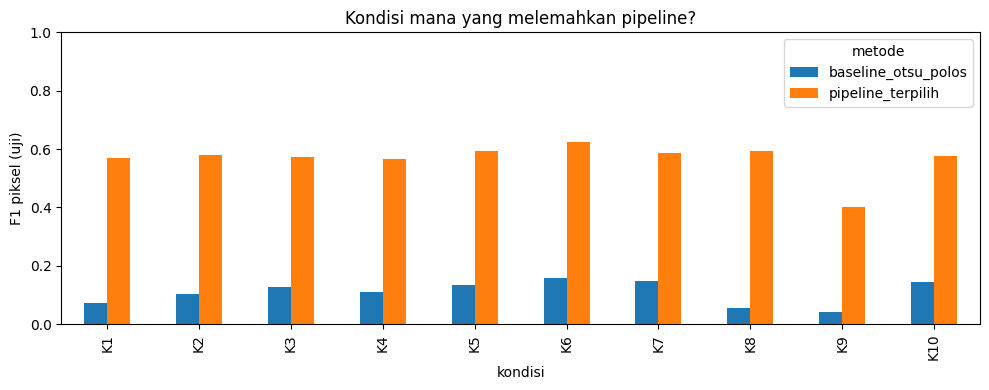

In [ ]:
reset_cache()
ev = {"pipeline_terpilih": evaluasi(uji, fn_pipeline(cfg)), "baseline_otsu_polos": evaluasi(uji, baseline_otsu_polos)}
res = pd.concat([e.assign(metode=n) for n, e in ev.items()], ignore_index=True)
res.to_csv(OUT + "/metrik_uji_per_citra.csv", index=False)
print("== Keseluruhan (UJI) ==")
display(res.groupby("metode")[["precision", "recall", "f1", "iou"]].mean().round(4))

urut = lambda idx: sorted(idx, key=lambda x: int(x[1:]))
pk = res.pivot_table(index="kondisi", columns="metode", values="f1").reindex(urut(res.kondisi.unique()))
pk.insert(0, "nama", [KONDISI.get(i, "") for i in pk.index])
pk.round(4).to_csv(OUT + "/metrik_uji_per_kondisi.csv")
print("== F1 per kondisi (UJI) ==")
display(pk.round(4))

ax = pk[["baseline_otsu_polos", "pipeline_terpilih"]].plot.bar(figsize=(10, 4), ylim=(0, 1))
ax.set_ylabel("F1 piksel (uji)"); ax.set_title("Kondisi mana yang melemahkan pipeline?")
plt.tight_layout(); plt.savefig(OUT + "/f1_per_kondisi.png", dpi=100); plt.show()

### Analisis statistik tambahan: sebaran per kondisi dan selang kepercayaan

In [ ]:
urut_k = lambda idx: sorted(idx, key=lambda x: int(x[1:]))

tabel = res.groupby(["kondisi", "metode"]).f1.agg(n="count", rata2="mean", std="std", min="min", max="max").round(3)
tabel = tabel.reindex(pd.MultiIndex.from_product([urut_k(res.kondisi.unique()), sorted(res.metode.unique())],
                                                  names=["kondisi", "metode"]))
tabel.to_csv(OUT + "/metrik_uji_per_kondisi_detail.csv")
print("== F1 per kondisi: n, rata-rata, std, min, max (UJI) ==")
display(tabel)


def ci_bootstrap(x, n=5000, seed=SEED):
    x = np.asarray(x, float)
    rng = np.random.RandomState(seed)
    rata = [rng.choice(x, len(x)).mean() for _ in range(n)]
    lo, hi = np.percentile(rata, [2.5, 97.5])
    return x.mean(), lo, hi


p = res.pivot_table(index="file", columns="metode", values="f1")
selisih = p["pipeline_terpilih"] - p["baseline_otsu_polos"]
ci = pd.DataFrame([(nama,) + ci_bootstrap(x) for nama, x in (("F1 pipeline", p["pipeline_terpilih"]),
                                                           ("F1 baseline Otsu", p["baseline_otsu_polos"]),
                                                           ("Selisih pipeline - baseline", selisih))],
                  columns=["besaran", "rata2", "CI95_bawah", "CI95_atas"]).round(4)
ci.to_csv(OUT + "/ci_bootstrap.csv", index=False)
print(f"== Bootstrap 95% (n={len(p)} citra uji) ==")
display(ci)
print("Catatan: citra dari lembar yang sama saling berkorelasi, jadi CI ini hanya perkiraan kasar.")

print("== K9 per citra (UJI) ==")
display(res[res.kondisi == "K9"][["file", "metode", "precision", "recall", "f1"]].round(3).sort_values(["file", "metode"]))

dk9 = dev[dev.kondisi == "K9"]
d_pipe = evaluasi(dk9, fn_pipeline(cfg)).assign(metode="pipeline_terpilih")
d_base = evaluasi(dk9, baseline_otsu_polos).assign(metode="baseline_otsu_polos")
print("== K9 per citra (DEV) ==")
display(pd.concat([d_pipe, d_base])[["file", "metode", "precision", "recall", "f1"]].round(3).sort_values(["file", "metode"]))

== F1 per kondisi: n, rata-rata, std, min, max (UJI) ==


n  rata2    std    min    max
kondisi metode                                            
K1      baseline_otsu_polos  2  0.073  0.010  0.066  0.080
        pipeline_terpilih    2  0.569  0.002  0.568  0.570
K2      baseline_otsu_polos  2  0.102  0.014  0.092  0.112
        pipeline_terpilih    2  0.579  0.061  0.536  0.622
K3      baseline_otsu_polos  2  0.126  0.013  0.117  0.135
        pipeline_terpilih    2  0.574  0.021  0.559  0.589
K4      baseline_otsu_polos  2  0.111  0.000  0.111  0.111
        pipeline_terpilih    2  0.566  0.042  0.536  0.595
K5      baseline_otsu_polos  2  0.133  0.009  0.126  0.139
        pipeline_terpilih    2  0.593  0.055  0.555  0.632
K6      baseline_otsu_polos  2  0.160  0.013  0.150  0.169
        pipeline_terpilih    2  0.625  0.001  0.624  0.626
K7      baseline_otsu_polos  2  0.147  0.021  0.132  0.162
        pipeline_terpilih    2  0.586  0.046  0.553  0.619
K8      baseline_otsu_polos  2  0.057  0.009  0.050  0.063
        pipeline_terpilih    2  0.592  0.110  0.514  0.670
K9      baseline_otsu_polos  2  0.041  0.004  0.039  0.044
        pipeline_terpilih    2  0.402  0.144  0.300  0.504
K10     baseline_otsu_polos  2  0.146  0.010  0.138  0.153
        pipeline_terpilih    2  0.576  0.058  0.535  0.617

== Bootstrap 95% (n=20 citra uji) ==


,besaran,rata2,CI95_bawah,CI95_atas
0,F1 pipeline,0.5663,0.5296,0.5950
1,F1 baseline Otsu,0.1094,0.0917,0.1267
2,Selisih pipeline - baseline,0.4569,0.4257,0.4849


Catatan: citra dari lembar yang sama saling berkorelasi, jadi CI ini hanya perkiraan kasar.
== K9 per citra (UJI) ==


,file,metode,precision,recall,f1
29,B_K9.png,baseline_otsu_polos,0.020,0.487,0.039
9,B_K9.png,pipeline_terpilih,0.662,0.406,0.504
39,E_K9.png,baseline_otsu_polos,0.023,0.778,0.044
19,E_K9.png,pipeline_terpilih,0.383,0.247,0.300


== K9 per citra (DEV) ==


,file,metode,precision,recall,f1
0,A_K9.png,baseline_otsu_polos,0.022,0.836,0.044
0,A_K9.png,pipeline_terpilih,0.473,0.139,0.215
1,C_K9.png,baseline_otsu_polos,0.031,0.841,0.059
1,C_K9.png,pipeline_terpilih,0.713,0.400,0.512
2,D_K9.png,baseline_otsu_polos,0.021,0.563,0.041
2,D_K9.png,pipeline_terpilih,0.521,0.385,0.443


## Langkah 6: Analisis kegagalan (tiga citra uji terburuk)

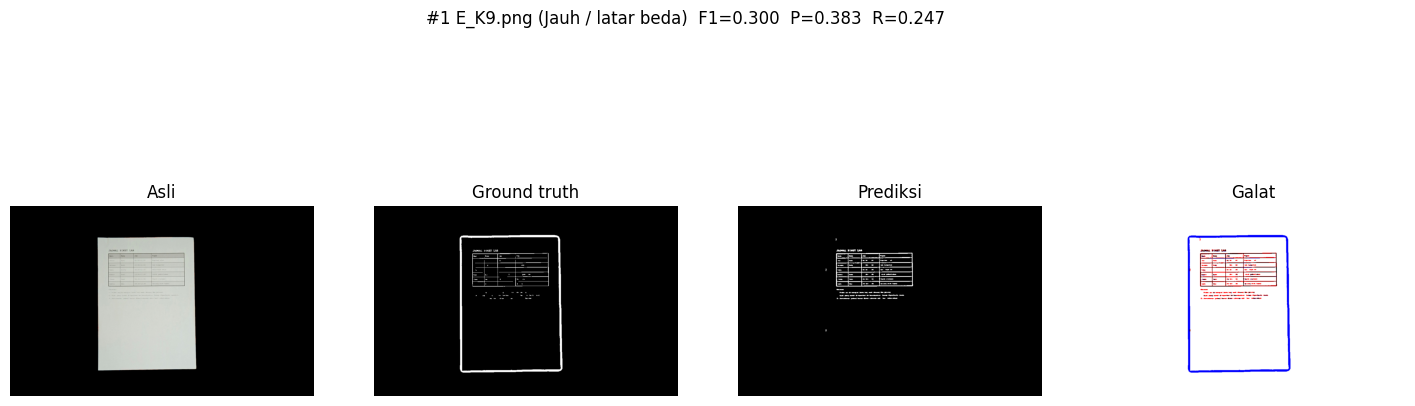

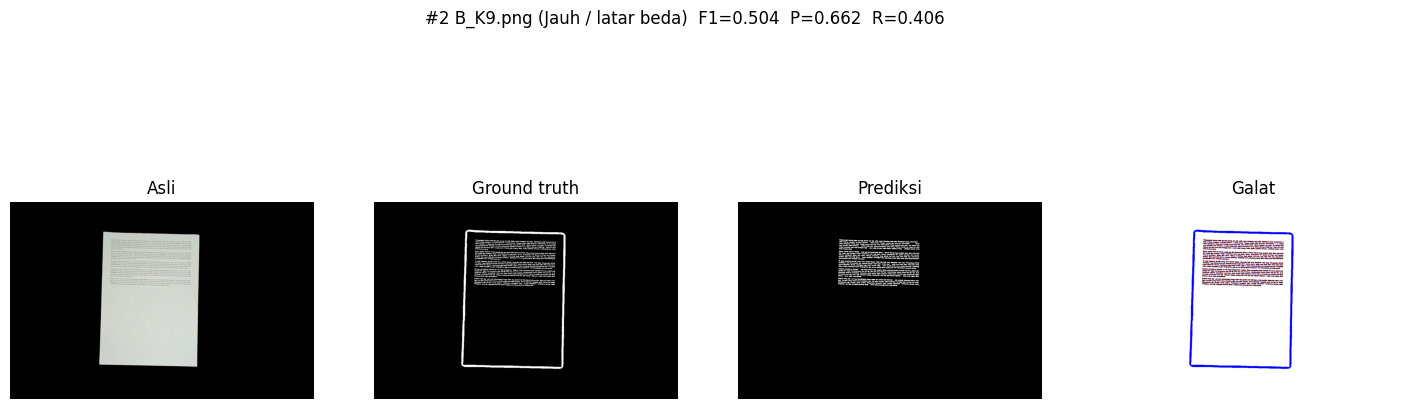

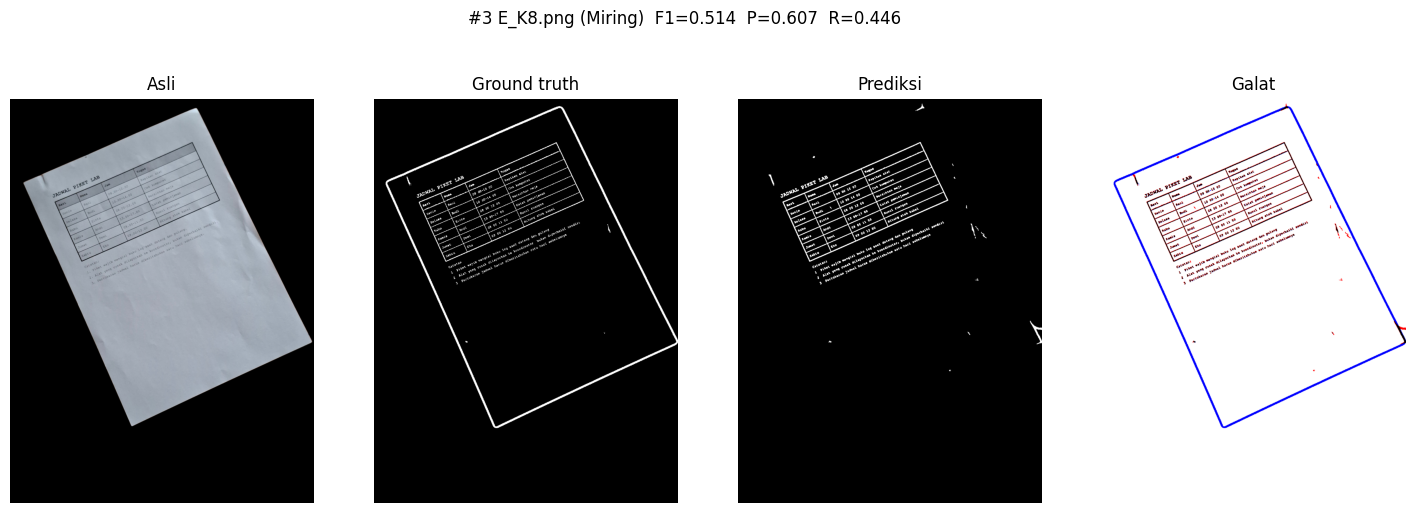

,file,kondisi,precision,recall,f1,iou,petunjuk_awal
0,E_K9.png,K9,0.3831,0.2469,0.3003,0.1767,"Banyak tinta hilang (biru): cek tahap 3 (ambang terlalu ketat, goresan tipis) dan tahap 4 (opening/min_area terlalu ..."
1,B_K9.png,K9,0.6623,0.4062,0.5036,0.3365,"Banyak tinta hilang (biru): cek tahap 3 (ambang terlalu ketat, goresan tipis) dan tahap 4 (opening/min_area terlalu ..."
2,E_K8.png,K8,0.6073,0.4459,0.5142,0.3461,"Banyak tinta hilang (biru): cek tahap 3 (ambang terlalu ketat, goresan tipis) dan tahap 4 (opening/min_area terlalu ..."


In [ ]:
gagal = analisis_kegagalan(uji, cfg, OUT)
display(gagal)

## Langkah 7: Simpan citra biner dan unduh semua hasil

In [ ]:
for _, r in df.iterrows():
    nama = re.sub(r"[^A-Za-z0-9_]", "_", os.path.splitext(r["file"])[0])
    cv2.imwrite(f"{OUT}/biner/{nama}.png", pipeline_binerisasi(r["citra"], **cfg))
import shutil
shutil.make_archive(BASE + "/hasil_uts", "zip", OUT)
print("Hasil tersimpan di", OUT)
if IN_COLAB:
    from google.colab import files
    files.download(BASE + "/hasil_uts.zip")

Hasil tersimpan di /content/uts_topik3/hasil


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>